**MONTE CARLO SIMULATION TO OPTIMIZE THE WEIGHT OF EACH STOCK IN A PORTFOLIO**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import seaborn as sns

import ipywidgets as widgets
from IPython.display import display, clear_output

IMPORT THE DAILY CLOSE DATA OF EACH ASSET TO GENERATE AN INTERACTIVE INTERFACE BETWEEN USER AND CODE: 

In [2]:
start = '2015-01-01'
end   = '2026-01-01'

ACTIVOS = {
    'AAPL': 'Apple',    'MSFT': 'Microsoft',    'GOOGL': 'Alphabet',    'AMZN': 'Amazon',
    'NVDA': 'NVIDIA',   'META': 'Meta',    'TSLA': 'Tesla',    'JPM': 'JPMorgan',    'GS': 'Goldman Sachs',
    'XOM': 'ExxonMobil',    'V': 'Visa',    'NFLX': 'Netflix',    'SPY': 'S&P 500 ETF',    'GLD': 'Gold ETF',
    'BRK-B': 'Berkshire Hathaway',    'JNJ': 'Johnson & Johnson',    'WMT': 'Walmart',    'PG': 'Procter & Gamble',
    'KO': 'Coca-Cola',    'PEP': 'PepsiCo',    'DIS': 'Disney',    'INTC': 'Intel',
    'CSCO': 'Cisco',    'ABT': 'Abbott Laboratories',    'CRM': 'Salesforce',
    'ADBE': 'Adobe',}

selects = [
    widgets.Dropdown(
        options=[(f'{t} — {n}', t) for t, n in ACTIVOS.items()],
        description=f'Activo {i+1}:',
        style={'description_width': '80px'},
        layout=widgets.Layout(width='260px')
    )
    for i in range(4)
]

btn    = widgets.Button(description='Download data', button_style='primary')
output = widgets.Output()

def on_click(b):
    tickers = [s.value for s in selects]
    global portfolio 
    if len(set(tickers)) < 4:
        with output:
            clear_output()
            print('⚠ Selecciona 4 activos distintos.')
        return

    with output:
        clear_output()
        series = {}
        for t in tickers:
            var_name = t.lower().replace('-', '_')
            data = yf.download(t, start, end, progress=False)['Close']
            series[t] = data
            globals()[var_name] = data

        portfolio = pd.concat(series, axis=1, sort=False)
        portfolio.columns = tickers
        print('Portfolio created')

btn.on_click(on_click)

display(widgets.VBox(selects + [btn, output]))


INITIAL UNDERSTANDING

- Each asset's performance is analyzed visually and individually

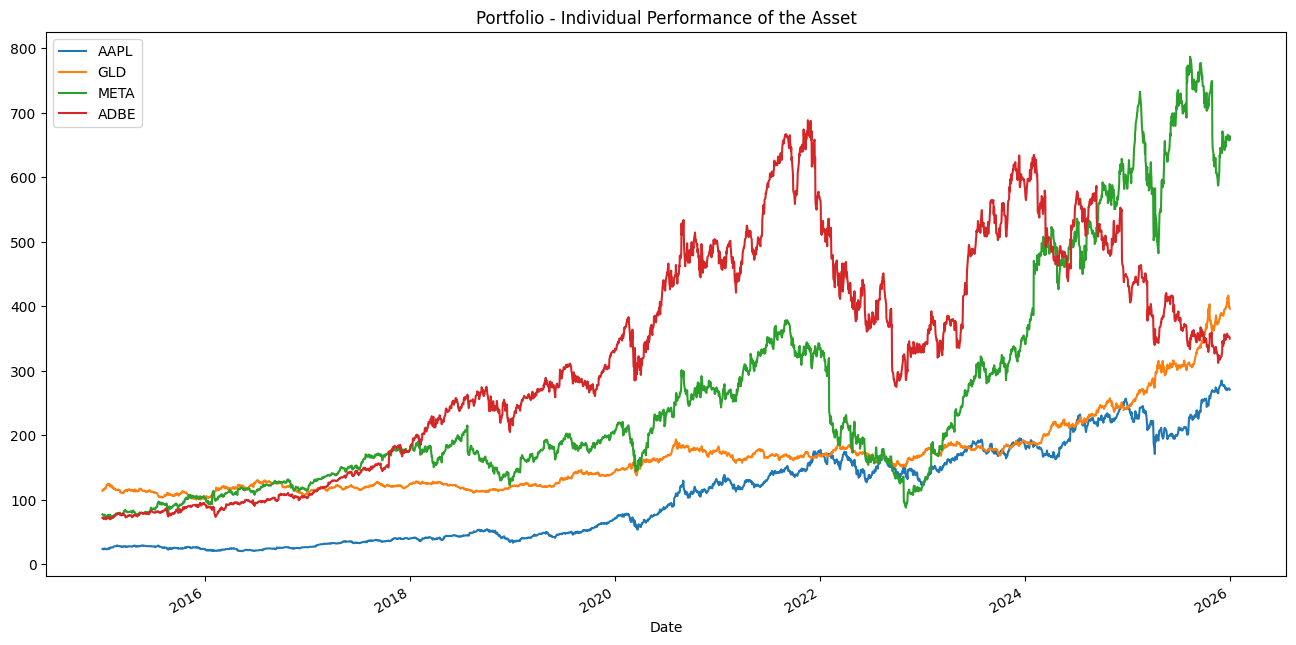

In [3]:
portfolio = portfolio.dropna()
    
portfolio.plot(figsize=(16,8));
plt.title('Portfolio - Individual Performance of the Asset');

- Next, the cumulative return of each asset is calculated and plotted:

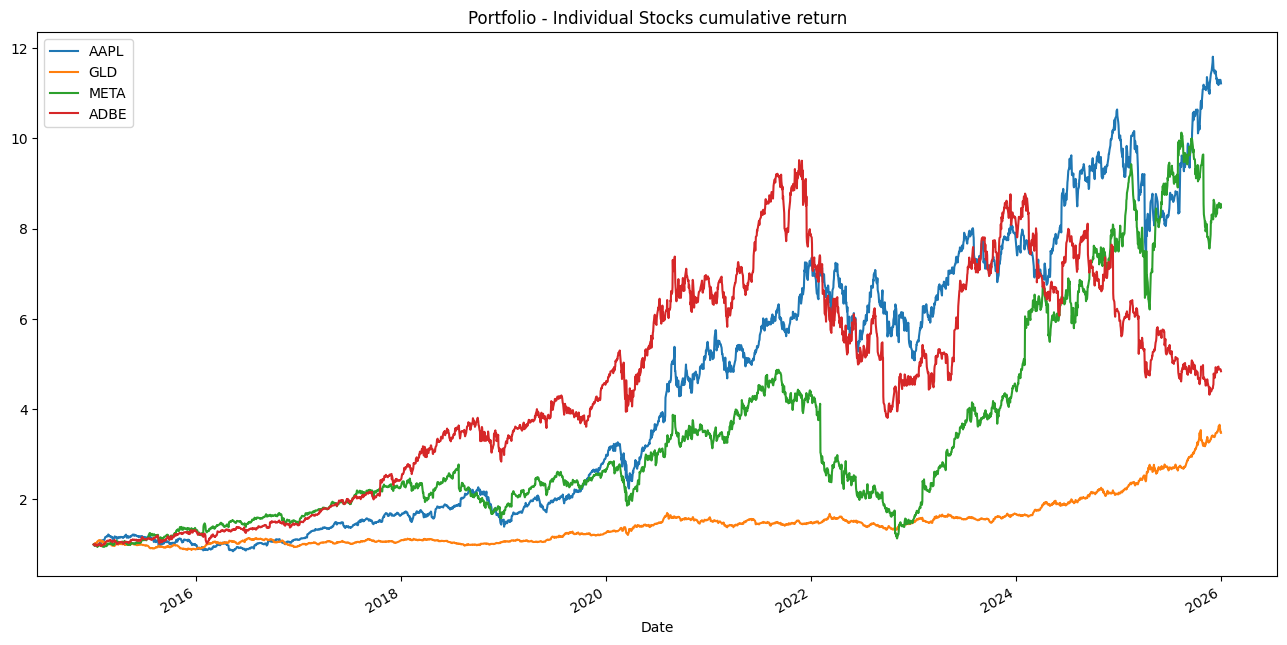

In [4]:
portfolio_cumretdaily = portfolio.copy()

for col in portfolio.columns:
    portfolio_cumretdaily[col] = (portfolio_cumretdaily[col]/portfolio_cumretdaily[col].iloc[0])
    
portfolio_cumretdaily.plot(figsize=(16,8));
plt.title('Portfolio - Individual Stocks cumulative return');

- Finally, the correlation between assets is observed using the covariance matrix:


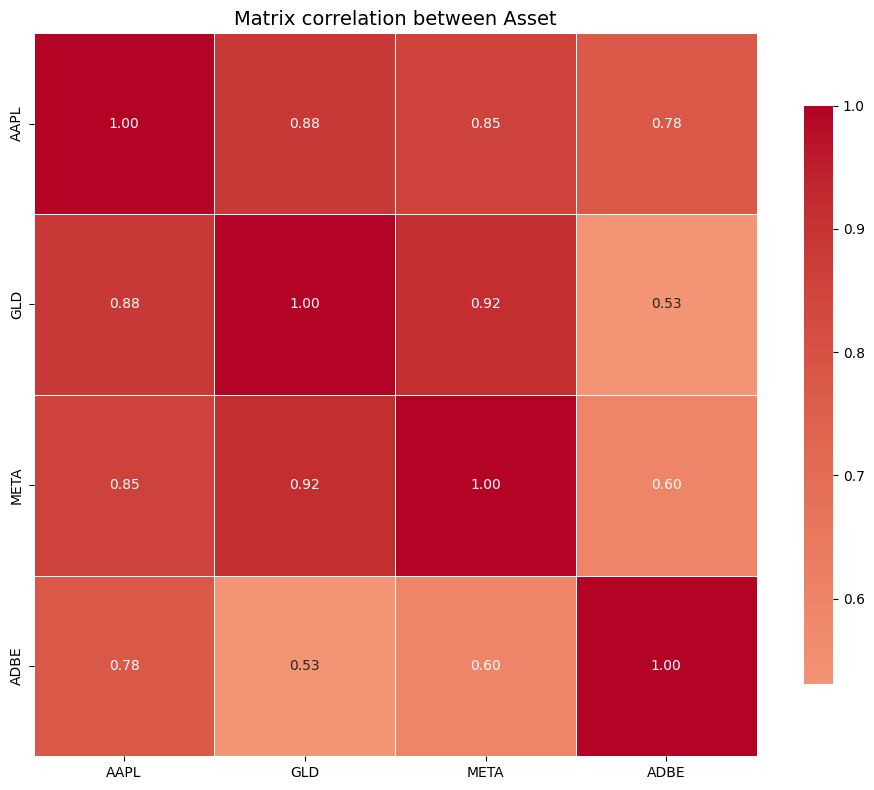

In [5]:
# Calcular matriz de correlación
corr_matrix = portfolio.corr()

# Configurar el tamaño de la figura
plt.figure(figsize=(10, 8))

# Heatmap de correlaciones
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm',center=0,fmt='.2f',square=True,linewidths=0.5,cbar_kws={"shrink": 0.8})

plt.title('Matrix correlation between Asset', fontsize=14)
plt.tight_layout()
plt.show()

- Correlations close to one indicate assets that move identically.
- Correlations close to zero indicate assets that move differently and without a fixed pattern between them.
- Correlations close to negative one indicate assets that move identically but in opposite directions.

THE CUMULATIVE RETURN RATE IS CALCULATED BY ASSIGNING A RANDOM WEIGHT TO EACH ASSET

- The portfolio return is calculated by assigning a random weight to each asset and stored in a variable called 'portfolio_randallo':

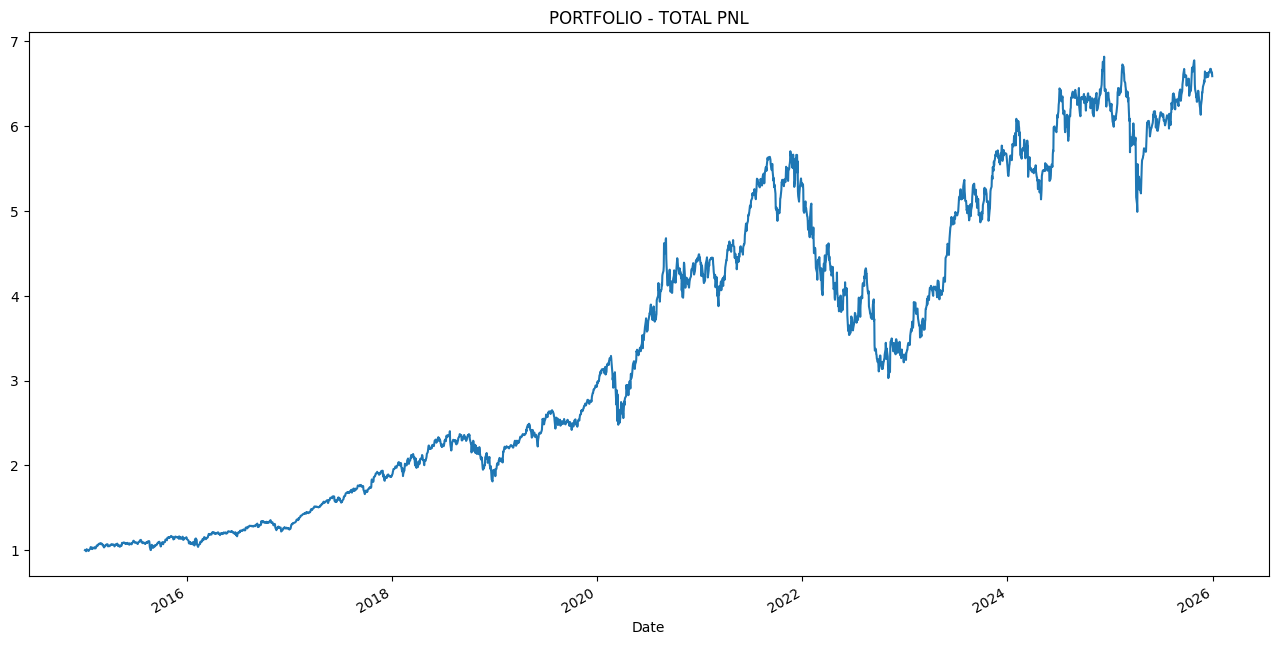

In [6]:
allo = np.random.random(4)
allo = allo/sum(allo) # Para que nunca se pase del 100%
portfolio_randallo = portfolio.copy()

for col,a in zip(portfolio_randallo.columns,allo):
    portfolio_randallo[col] = (portfolio_randallo[col]/portfolio_randallo[col].iloc[0])*a
    
portfolio_randallo['ret_daily'] = portfolio_randallo.sum(axis=1)/portfolio_randallo.sum(axis=1).iloc[0]

portfolio_randallo['ret_daily'].plot(figsize=(16,8));
plt.title('PORTFOLIO - TOTAL PNL');

(This is the idea of the Monte Carlo simulation: assigning a very large number of different weights to find the most optimal result)

THE SHARPE RATIO IS CALCULATED TO EVALUATE PROFITABILITY AGAINST RISK

$$\text{Sharpe} = \frac{R_p - R_f}{\sigma_p}$$

Donde:
- $R_p$ = Portfolio return.
- $R_f$ = Risk-free rate.
- $\sigma_p$ = Portfolio volatility.

"Let's assume a risk-free rate of 2% for the calculation, understanding this parameter as the 'safe' return that a robust, low-volatility asset would provide us (Treasury bonds, interest rates...)"

- First, the daily returns of each asset are converted to a logarithmic scale:

In [7]:
portfolio_log = np.log(portfolio/portfolio.shift(1))

- Next, a 'for' loop is created that will provide the Monte Carlo simulation.



In [8]:
## Inicializo las variables que voy a usar ##
num_iter = 15000
all_weights = np.zeros((num_iter,len(portfolio.columns)))
ret_fix = 2/100
ret_portf = np.zeros(num_iter)
vol_portf = np.zeros((num_iter))
sp = np.zeros(num_iter)


## Creo bucle for donde se iterará ##
for it in range(num_iter):

    # Weights
    weights = np.random.random(4)
    weights = weights/np.sum(weights)
    all_weights[it,:] = weights

    # Portfolio return
    ret_portf[it] =  np.sum(portfolio_log.mean()*weights*252)

    # Portfolio volatility
    vol_portf[it] = np.sqrt(np.dot(weights.T,np.dot(portfolio_log.cov()*252,weights))) 

    # Sharpe Ratio
    sp[it] = (ret_portf[it]-ret_fix)/vol_portf[it]


- The Markowitz efficient frontier is then manually calculated:

Max sharpe ratio =  0.9330056434516865
AAPL, allocation: 33.87%
GLD, allocation: 61.77%
META, allocation: 3.09%
ADBE, allocation: 1.28%


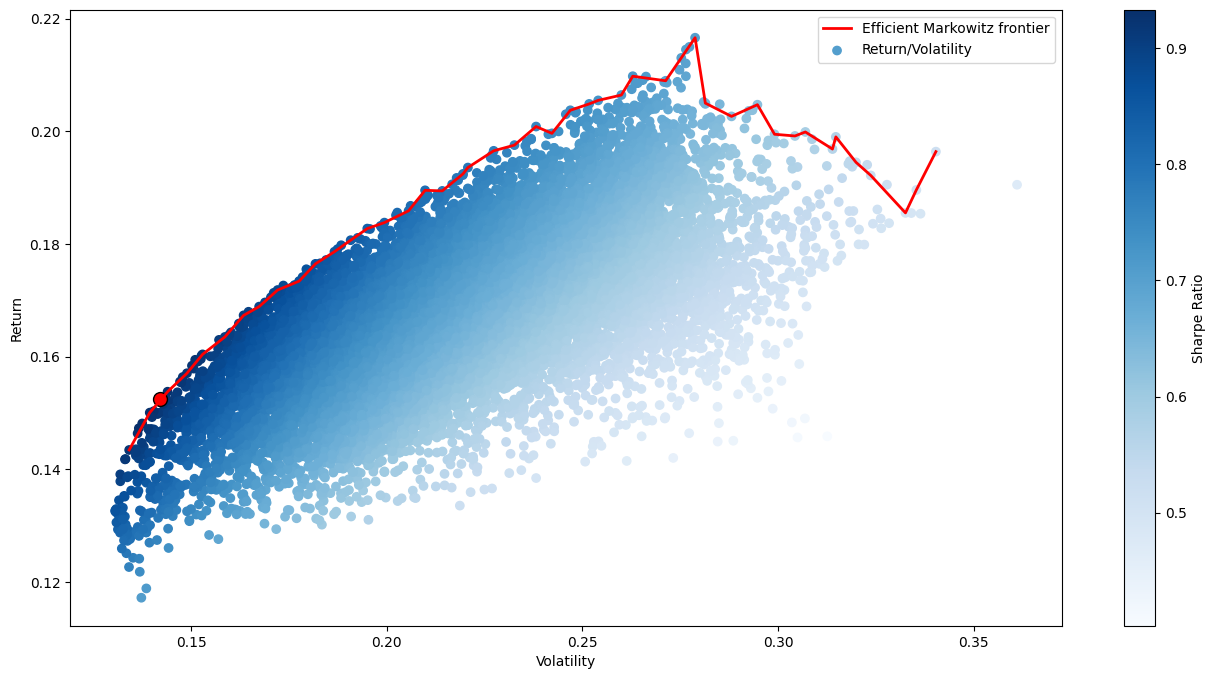

In [9]:
## Se desarrolla un bucle 'for' que abarca el eje x en intervalos equiespaciados donde, para cada uno de ellos, se seleccionará el mayor valor de retorno existente. ##
num_inter = 50
pasos = np.linspace(min(vol_portf),max(vol_portf),num_inter)
valuex = np.zeros((num_inter))
valuey = np.zeros((num_inter))


for it in range(len(pasos)-1):
    val = np.where((vol_portf>=pasos[it]) & (vol_portf<pasos[it+1]))
    if len(val[0]) > 0:
        idx = val[0][ret_portf[val].argmax()]
        valuex[it] = vol_portf[idx]
        valuey[it] = ret_portf[val].max()

## Allocations ##
max_vol_portf = vol_portf[sp.argmax()] # Volatility value wich maximize sharpe ratio
max_ret_portf = ret_portf[sp.argmax()] # Return value wich maximize sharpe ratio

## Se representa todo gráficamente ##
plt.figure(figsize=(16,8))
mascara = (valuex > 0) & (valuey > 0) # Filtro por elementos mayores a cero
orden = np.argsort(valuex[mascara])  

## Frontera Mark ##
plt.plot(valuex[mascara][orden], valuey[mascara][orden], c='red', linewidth=2, zorder=2,label = 'Efficient Markowitz frontier')

## Ratio Sharpe ##
plt.scatter(vol_portf, ret_portf, c=sp, cmap = 'Blues',zorder=1,label='Return/Volatility')
plt.colorbar(label='Sharpe Ratio')
plt.xlabel('Volatility')
plt.ylabel('Return')
plt.scatter(max_vol_portf,max_ret_portf,c='red',s=100,edgecolors='black');
plt.legend();

print('Max sharpe ratio = ',sp.max())
for nombre, a in zip(portfolio.columns, all_weights[sp.argmax()]):
    print(f'{nombre}, allocation: {a:.2%}')

**CONCLUSIONS**

The interpretation of the obtained Sharpe ratio is based on:

- A Sharpe ratio below 0 will indicate a portfolio less profitable than the risk-free asset.

- A Sharpe ratio between 0 and 1 indicates a profitable portfolio, but the risk taken may not be worth it.

- A Sharpe ratio between 1 and 2 is considered good; you assume risk, but it is offset.

- A Sharpe ratio between 2 and 3 is considered very good; it is difficult to maintain in the long term.

- A ratio above 3 begins to be suspicious. In backtesting, it usually indicates overfitting.

It should be noted that, if an asset is very profitable but at the same time very volatile, its weight in our optimal portfolio will be smaller than that of a less profitable but also less volatile asset.



**ASPECTS OBSERVED IN THE PROJECT DEVELOPMENT**

One way to improve our Sharpe Ratio would be to include an inversely correlated and profitable asset over the estimated time period for two key reasons to understand:

- Being inversely correlated, when one asset rises, the other falls, which translates into greater diversification, reducing the standard deviation (denominator).

- Being profitable in the long term, it contributes to the profitability of our portfolio, increasing it (we increase the numerator).